# Energy density of showers: global and local

Tasks 4 and 5 from Gábor (22/11/2026)

1. **Global density** $\bar\rho_{95} = E_{95}/V_{95}$: the energy inside the smallest set of $5\times5\times10$ cm boxes holding 95% of the event's visible energy, divided by their volume.
2. **3D density profile**: the shower in its own frame is cut into $5\times5\times10$ cm boxes; mean density per box for each particle.
3. **Local density within single showers**: the densest box of each event and the share of energy in "electron-like" dense boxes (candidate EM sub-showers).

> **Integrated into shape-form-particle.** Notebook by **Sofiya Kolesnyk** (particle issue #2, Q4 and Q5), as attached to the
> issue (original: `notebooks/sofiya/energy_density.ipynb`). Changes for the integration only: the data folder and the file lookup (the
> balanced s1 and s2 files, in one folder or in `regression-<particle>/` subfolders), the work tables in `cache/density/`, figures as PNG
> and the table in `results/density/`. The analysis is unchanged. Section 5 was added: the reproduction of her numbers, the two samples
> separately, per-event features, and the comparison with the core fraction of issue #1.
>
> **To run it yourself:** set `DATA_DIR` in the first code cell to your data folder (or the `LFHCAL_DATA` environment variable) and run
> all cells; DuckDB uses 3 GB unless `DUCKDB_MEMORY` is set. This notebook can be edited directly; `scripts/build_density_notebook.py`
> only re-imports a new version of the original and refuses to overwrite an edited notebook unless `--force` is given.

In [1]:
import os
_d = os.getcwd()                          # integration: find the repository root, so that the notebook runs from any folder
while not os.path.exists(os.path.join(_d, "ALL-README.md")) and os.path.dirname(_d) != _d:
    _d = os.path.dirname(_d)
if os.path.exists(os.path.join(_d, "ALL-README.md")):
    os.chdir(_d)
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, duckdb

# ---------- settings ----------
DATA_DIR = Path(os.environ.get("LFHCAL_DATA", "/home/user/data/simulations"))   # your data folder: edit this path or set LFHCAL_DATA
FILES = {                       # file name per particle, {s} = s1 / s2 (both seeds are combined)
    "electron": "electron_standalone_N100000_M0_20GeV_reg_balanced_{s}_v3.csv",
    "muon":     "muon_standalone_N100000_M0_20GeV_reg_balanced_{s}_v3.csv",
    "pion":     "pion_standalone_N100000_M0_20GeV_reg_balanced_{s}_v3.csv",
    "proton":   "proton_standalone_N100000_M0_20GeV_reg_balanced_{s}_v3.csv",
}


def find_files(name):
    """integration: the s1 and s2 file, one each, in DATA_DIR itself (a flat folder) or in DATA_DIR/regression-<particle>/"""
    out = []
    for s in ("s1", "s2"):
        f = name.format(s=s)
        hit = [c for c in (DATA_DIR / f, DATA_DIR / f"regression-{f.split('_')[0]}" / f) if c.exists()]
        out += hit[:1]
    return out

WORK_DIR = Path("cache/density"); WORK_DIR.mkdir(parents=True, exist_ok=True)       # integration: work tables (not in git)
FIG_DIR = Path("results/density"); FIG_DIR.mkdir(parents=True, exist_ok=True)      # integration: figures (PNG) and tables
DUCKDB_MEMORY = os.environ.get("DUCKDB_MEMORY", "3GB")    # your value; the server run sets 64GB

BOX_XY, BOX_Z = 50.0, 100.0     # mm: 5 x 5 x 10 cm boxes (Gabor)
BOX_L = BOX_XY * BOX_XY * BOX_Z / 1e6   # litres (1 L = 1e6 mm^3) -> 0.25 L
LAYER = 20.5                    # mm, layer pitch
AXIS_R = 50.0                   # mm, "vicinity" of the axis: +-5 cm (Gabor)
P_BINS = [(1, 2), (4, 5), (9, 10), (14, 15), (19, 20)]   # GeV/c, for the maps
COLORS = {"electron": "#2a78d6", "pion": "#e0612a", "proton": "#14976a", "muon": "#b07a00"}
print("box volume:", BOX_L, "L")

box volume: 0.25 L


## Step 1: hits → shower frame → three small tables

Same shower frame as `core.calculate_event_local_coordinates`: the origin is the energy-weighted centre of the event's first hit layer, and the axes are rotated by `incoming_theta`, `incoming_phi`. Boxes are centred on the axis ($x' , y' \in [-25, 25]$ mm is box 0).

Outputs per particle:
* `boxes_*`: energy per event and box $(i_x, i_y, i_z)$
* `layers_*`: energy per event and layer, total and within ±5 cm of the axis
* `events_*`: per event: momentum, total energy, core energy

Event ids combine the file (seed) and `event_number`, since both seeds reuse the same numbers.

In [2]:
def build(name, pattern):
    outs = [WORK_DIR / f"{t}_{name}.parquet" for t in ("boxes", "layers", "events")]
    if all(o.exists() for o in outs):
        print(f"{name}: cached"); return
    files = find_files(pattern)            # integration: flat folder or regression-<particle>/ subfolders
    if not files:
        print(f"{name}: no files match {pattern} -> skipped"); return
    print(f"{name}: {len(files)} file(s) ...", flush=True)
    con = duckdb.connect()
    con.execute(f"SET memory_limit='{DUCKDB_MEMORY}'")
    con.execute("SET preserve_insertion_order=false")
    con.execute(f"SET temp_directory='{(WORK_DIR / 'tmp').as_posix()}'")
    flist = "[" + ",".join(f"'{f.as_posix()}'" for f in files) + "]"
    con.execute(f"""
        CREATE TEMP TABLE raw AS
        SELECT filename AS fn, event_number AS ev, x, y, z, energy AS e,
               incoming_momentum AS p, incoming_theta AS th, incoming_phi AS ph
        FROM read_csv({flist}, filename=true, header=true)
        WHERE energy > 0""")
    con.execute("""
        CREATE TEMP TABLE fid AS
        SELECT fn, row_number() OVER (ORDER BY fn) AS fid FROM (SELECT DISTINCT fn FROM raw)""")
    con.execute("CREATE TEMP TABLE z0 AS SELECT fn, ev, min(z) AS z0 FROM raw GROUP BY fn, ev")
    con.execute("""
        CREATE TEMP TABLE org AS
        SELECT r.fn, r.ev, sum(r.x*r.e)/sum(r.e) AS x0, sum(r.y*r.e)/sum(r.e) AS y0, any_value(z0.z0) AS z0
        FROM raw r JOIN z0 USING (fn, ev) WHERE r.z = z0.z0 GROUP BY r.fn, r.ev""")
    con.execute("""
        CREATE TEMP TABLE loc AS
        SELECT event, p, e, dz,
               dx*cos(th)*cos(ph) + dy*cos(th)*sin(ph) - dz*sin(th) AS xl,
              -dx*sin(ph) + dy*cos(ph)                             AS yl,
               dx*sin(th)*cos(ph) + dy*sin(th)*sin(ph) + dz*cos(th) AS zl
        FROM (SELECT f.fid * 10000000 + r.ev AS event, r.p, r.e, r.th, r.ph,
                     r.x - o.x0 AS dx, r.y - o.y0 AS dy, r.z - o.z0 AS dz
              FROM raw r JOIN org o USING (fn, ev) JOIN fid f USING (fn))""")
    con.execute("DROP TABLE raw")
    con.execute(f"""COPY (
        SELECT event, any_value(p) AS p,
               CAST(floor((xl + {BOX_XY/2}) / {BOX_XY}) AS INTEGER) AS ix,
               CAST(floor((yl + {BOX_XY/2}) / {BOX_XY}) AS INTEGER) AS iy,
               CAST(floor(zl / {BOX_Z}) AS INTEGER) AS iz,
               sum(e) AS E
        FROM loc GROUP BY event, ix, iy, iz) TO '{outs[0].as_posix()}' (FORMAT parquet)""")
    con.execute(f"""COPY (
        SELECT event, CAST(round(dz / {LAYER}) AS INTEGER) AS k,
               sum(e) AS E_layer,
               sum(CASE WHEN xl*xl + yl*yl < {AXIS_R**2} THEN e ELSE 0 END) AS E_axis
        FROM loc GROUP BY event, k) TO '{outs[1].as_posix()}' (FORMAT parquet)""")
    con.execute(f"""COPY (
        SELECT event, any_value(p) AS p, sum(e) AS E, count(*) AS n_hits,
               sum(CASE WHEN xl*xl + yl*yl < {AXIS_R**2} THEN e ELSE 0 END) AS E_core
        FROM loc GROUP BY event) TO '{outs[2].as_posix()}' (FORMAT parquet)""")
    n = con.execute("SELECT count(DISTINCT event) FROM loc").fetchone()[0]
    con.close()
    print(f"   {n} events done", flush=True)

for name, pat in FILES.items():
    build(name, pat)
NAMES = [n for n in FILES if (WORK_DIR / f"events_{n}.parquet").exists()]
print("available:", NAMES)

electron: cached
muon: cached
pion: cached
proton: cached
available: ['electron', 'muon', 'pion', 'proton']


## Step 2: global energy density per event

For each event, the boxes are sorted from densest to emptiest and taken until they hold 95% of the visible energy. That gives the containment volume $V_{95}$ (a multiple of 0.25 L) and

$$\bar\rho_{95} = \frac{E_{95}}{V_{95}} \quad [\text{MeV/L, visible energy}].$$

This is model-free and defined event by event, so it can later serve directly as a classification feature. The densest single box, $\rho_{\max}$, is kept as well.

In [3]:
def per_event(name):
    b = pd.read_parquet(WORK_DIR / f"boxes_{name}.parquet", columns=["event", "p", "E"])
    b = b[b.E > 0].sort_values(["event", "E"], ascending=[True, False])
    g = b.groupby("event", sort=False).E
    tot, cum = g.transform("sum"), g.cumsum()
    inside = (cum - b.E) < 0.95 * tot
    ev = b[inside].groupby("event").agg(p=("p", "first"), n95=("E", "size"), E95=("E", "sum"))
    ev["E_tot"] = g.sum()
    ev["E_max_box"] = g.max()
    ev["V95_L"] = ev.n95 * BOX_L
    ev["rho95"] = 1000 * ev.E95 / ev.V95_L            # MeV / L
    ev["rho_max"] = 1000 * ev.E_max_box / BOX_L       # MeV / L
    ev["pbin"] = np.floor(ev.p).astype(int)
    return ev

EV = {n: per_event(n) for n in NAMES}

rows = []
for n, ev in EV.items():
    for pb, g in ev.groupby("pbin"):
        rows.append(dict(particle=n, bin=f"{pb}-{pb+1}", n_events=len(g),
                         E_vis_MeV=1000 * g.E_tot.mean(), V95_L=g.V95_L.mean(),
                         rho95_median=g.rho95.median(),
                         rho_ratio_of_means=1000 * g.E95.mean() / g.V95_L.mean()))
GLOBAL = pd.DataFrame(rows)
GLOBAL.to_csv(FIG_DIR / "global_density_table.csv", index=False)
display(GLOBAL.pivot(index="bin", columns="particle", values="rho95_median").round(2)
        .sort_index(key=lambda s: s.str.split("-").str[0].astype(int)))

particle,electron,muon,pion,proton
bin,,,,
0-1,10.82,8.74,8.44,15.03
1-2,22.78,9.22,9.43,10.21
2-3,32.48,9.61,10.05,8.67
3-4,40.93,9.92,10.73,9.11
4-5,49.15,10.12,12.04,9.80
5-6,56.50,10.21,13.57,10.36
6-7,64.05,10.29,15.14,11.01
7-8,71.31,10.36,16.14,11.90
8-9,77.71,10.33,16.92,12.61


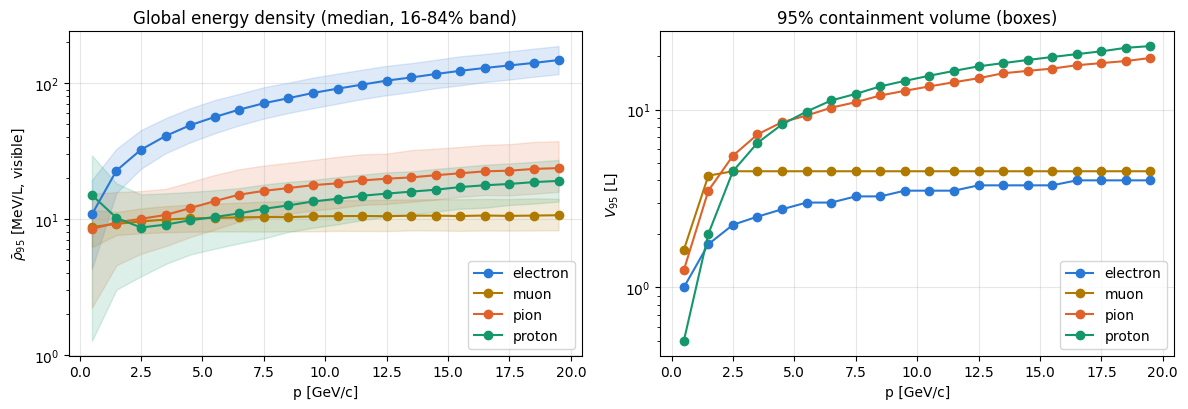

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for n, ev in EV.items():
    s = ev.groupby("pbin").rho95.describe(percentiles=[.16, .5, .84])
    x = s.index + 0.5
    ax[0].plot(x, s["50%"], "o-", color=COLORS[n], label=n)
    ax[0].fill_between(x, s["16%"], s["84%"], color=COLORS[n], alpha=.15)
    v = ev.groupby("pbin").V95_L.median()
    ax[1].plot(v.index + 0.5, v, "o-", color=COLORS[n], label=n)
ax[0].set(yscale="log", xlabel="p [GeV/c]", ylabel=r"$\bar\rho_{95}$ [MeV/L, visible]",
          title="Global energy density (median, 16-84% band)")
ax[1].set(yscale="log", xlabel="p [GeV/c]", ylabel=r"$V_{95}$ [L]", title="95% containment volume (boxes)")
for a in ax: a.legend(); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "global_density.png", dpi=130); plt.show()

**Optional: density with the drop volumes.** 

In [5]:
DROP_V = {
    "electron": [51.27, 43.34, 34.33, 25.03, 25.72, 20.31, 32.76, 25.19, 24.03, 23.99,
                 23.01, 20.46, 18.21, 25.39, 20.46, 21.77, 21.91, 21.92, 26.20, 16.61],
    # "pion":   [...],   # from 03_drop_pion
    # "proton": [...],   # from 03_drop_proton
}
rows = []
for n, V in DROP_V.items():
    if n not in EV: continue
    E = EV[n].groupby("pbin").E_tot.mean()
    for pb, v in enumerate(V):
        if pb in E.index:
            rows.append(dict(particle=n, bin=f"{pb}-{pb+1}", V_drop_L=v,
                             E_vis_MeV=1000 * E[pb], rho_drop=0.95 * 1000 * E[pb] / v))
display(pd.DataFrame(rows).round(3))

,particle,bin,V_drop_L,E_vis_MeV,rho_drop
0,electron,0-1,51.27,13.279,0.246
1,electron,1-2,43.34,42.391,0.929
2,electron,2-3,34.33,73.633,2.038
3,electron,3-4,25.03,104.803,3.978
4,electron,4-5,25.72,136.231,5.032
5,electron,5-6,20.31,168.183,7.867
6,electron,6-7,32.76,200.013,5.800
7,electron,7-8,25.19,231.728,8.739
8,electron,8-9,24.03,263.142,10.403
9,electron,9-10,23.99,295.374,11.697


## Step 3: the 3D density profile (5 × 5 × 10 cm boxes)

Mean density of each box over all events of a momentum bin:

$$\rho(i_x,i_y,i_z) = \frac{1}{N_{\rm ev}}\sum_{\rm events}\frac{E_{\rm box}}{0.25\ \text{L}}.$$

Shown: a slice through the axis ($i_y = 0$), the profile along the axis box ($i_x=i_y=0$), and the transverse profile (rings of boxes around the axis).

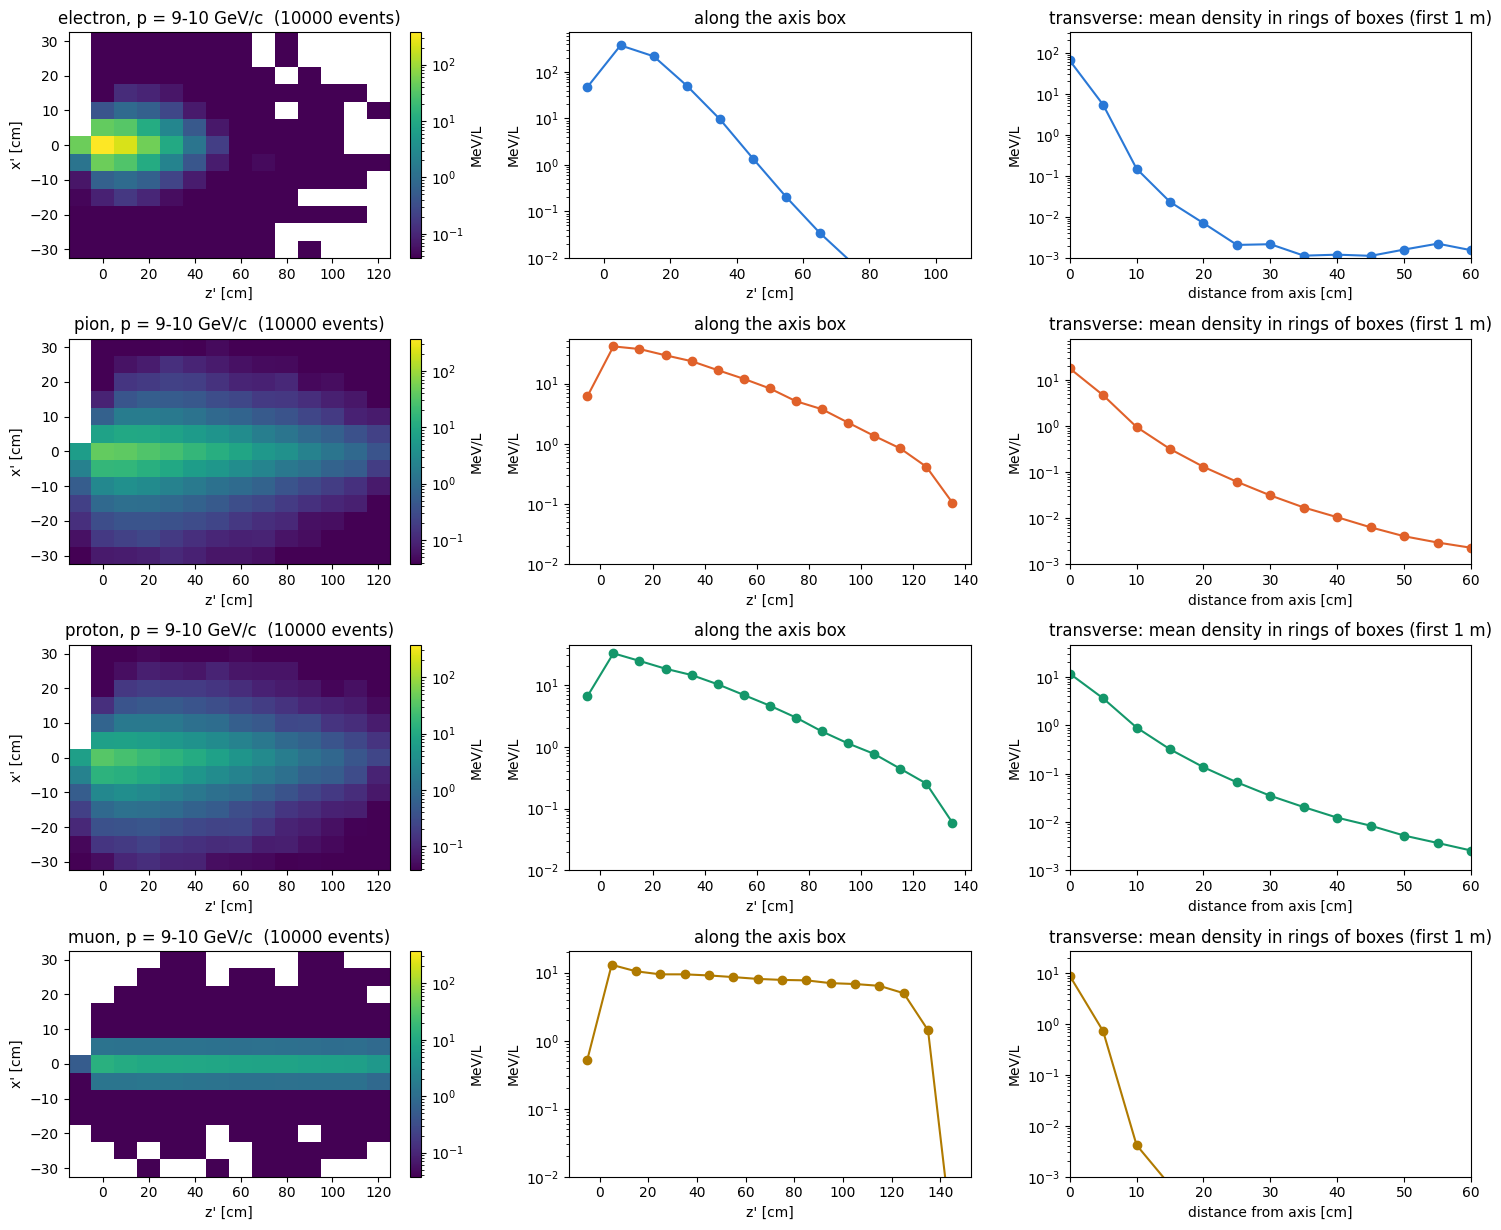

In [6]:
def mean_map(name, lo, hi):
    b = pd.read_parquet(WORK_DIR / f"boxes_{name}.parquet", filters=[("p", ">=", lo), ("p", "<", hi)])
    nev = b.event.nunique()
    m = (b.groupby(["ix", "iy", "iz"]).E.sum() / max(nev, 1) * 1000 / BOX_L).rename("rho").reset_index()
    return m, nev

def plot_profiles(lo, hi, names=("electron", "pion", "proton", "muon")):
    names = [n for n in names if n in NAMES]
    fig, ax = plt.subplots(len(names), 3, figsize=(15, 3.1 * len(names)), squeeze=False)
    vmax = None
    for row, n in enumerate(names):
        m, nev = mean_map(n, lo, hi)
        sl = m[m.iy == 0].pivot(index="ix", columns="iz", values="rho")
        sl = sl.reindex(index=range(-6, 7), columns=range(-1, 13)).fillna(0)
        vmax = vmax or max(sl.values.max(), 1e-9)
        im = ax[row, 0].pcolormesh(sl.columns * BOX_Z / 10, sl.index * BOX_XY / 10, sl.values,
                                   norm=plt.matplotlib.colors.LogNorm(vmin=vmax * 1e-4, vmax=vmax), shading="nearest")
        ax[row, 0].set(title=f"{n}, p = {lo}-{hi} GeV/c  ({nev} events)", xlabel="z' [cm]", ylabel="x' [cm]")
        fig.colorbar(im, ax=ax[row, 0], label="MeV/L")
        a = m[(m.ix == 0) & (m.iy == 0)].sort_values("iz")
        ax[row, 1].semilogy(a.iz * BOX_Z / 10 + BOX_Z / 20, a.rho, "o-", color=COLORS[n])
        ax[row, 1].set(title="along the axis box", xlabel="z' [cm]", ylabel="MeV/L")
        m["ring"] = np.maximum(m.ix.abs(), m.iy.abs())
        d = m[(m.iz >= 0) & (m.iz < 10)]                                   # first 1 m of depth
        n_geo = lambda k: 1 if k == 0 else 8 * k                            # boxes in ring k
        rg = d.groupby("ring").rho.sum() / [n_geo(k) * 10 for k in d.groupby("ring").rho.sum().index]
        ax[row, 2].semilogy(rg.index * BOX_XY / 10, rg.values, "o-", color=COLORS[n])
        ax[row, 2].set(title="transverse: mean density in rings of boxes (first 1 m)", xlabel="distance from axis [cm]", ylabel="MeV/L")
    for a in ax[:, 2]: a.set_xlim(0, 60); a.set_ylim(1e-3, None)
    for a in ax[:, 1]: a.set_ylim(1e-2, None)
    fig.tight_layout(); fig.savefig(FIG_DIR / f"density_profile_{lo}_{hi}GeV.png", dpi=130); plt.show()

plot_profiles(9, 10)

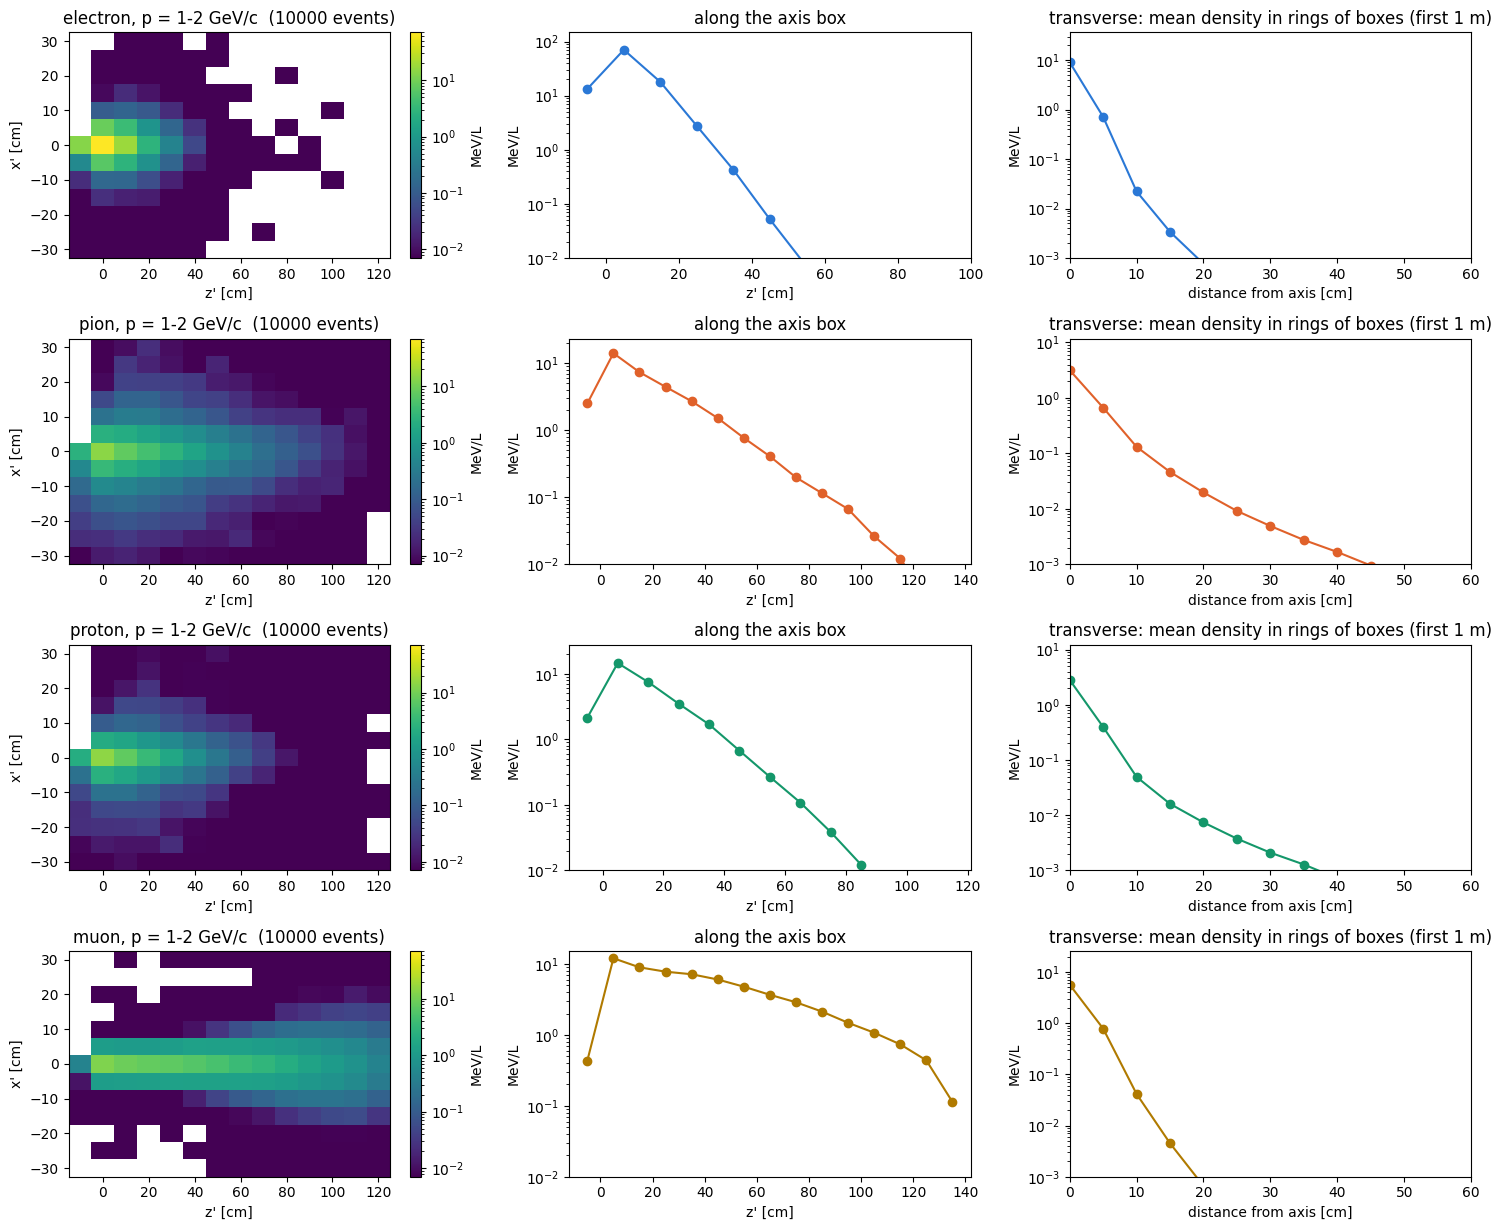

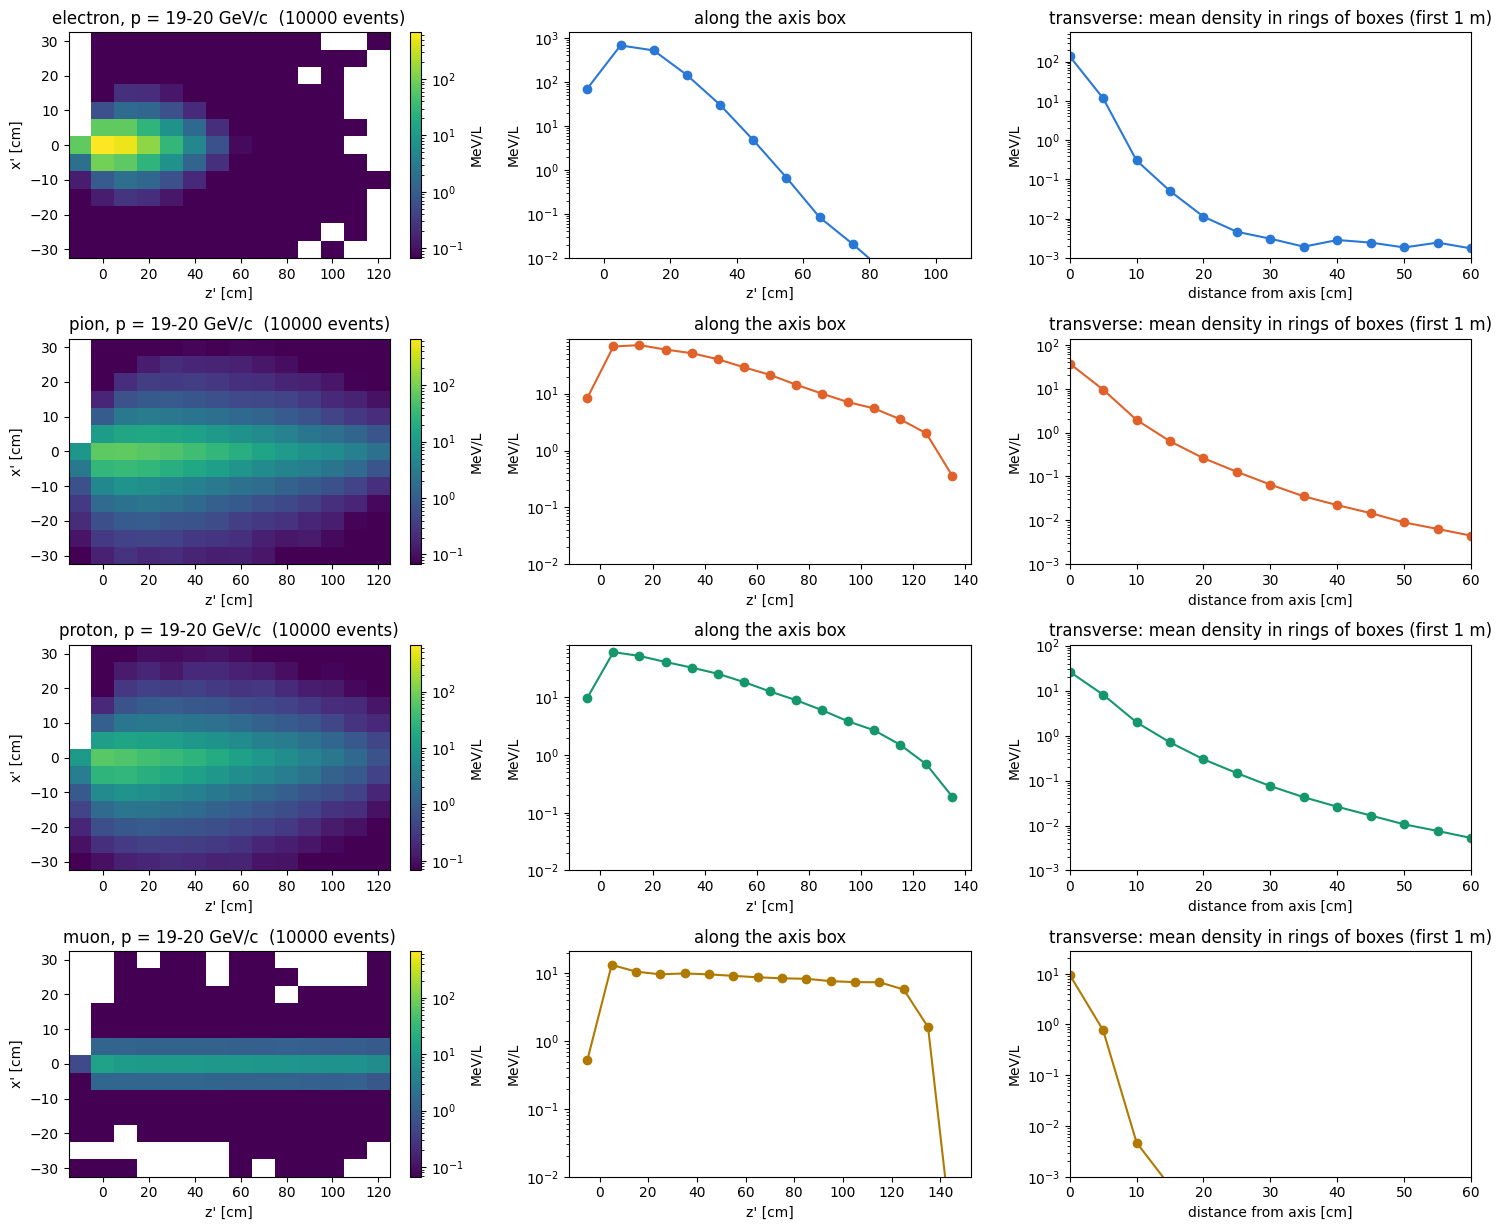

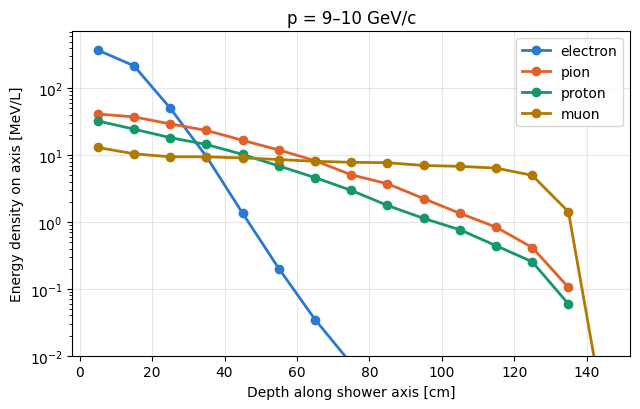

In [7]:
for lo, hi in [(1, 2), (19, 20)]:      # other momenta; add more from P_BINS if useful
    plot_profiles(lo, hi)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for n in ["electron", "pion", "proton", "muon"]:
    m, nev = mean_map(n, 9, 10)
    a = m[(m.ix == 0) & (m.iy == 0) & (m.iz >= 0)].sort_values("iz")
    ax.semilogy(a.iz * BOX_Z / 10 + BOX_Z / 20, a.rho, "o-", color=COLORS[n], label=n, lw=2)
ax.set(xlabel="Depth along shower axis [cm]", ylabel="Energy density on axis [MeV/L]",
       title="p = 9–10 GeV/c", ylim=(1e-2, None))
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(FIG_DIR / "axis_density_overlay_9_10GeV.png", dpi=130); plt.show()

## Step 4: local density inside single showers

An electron shower is dense; a hadron shower is dilute on average. But if a hadron shower contains an EM sub-shower ($\pi^0\to\gamma\gamma$), some of its boxes should reach electron-like densities.

Per event:
* $\rho_{\max}$: the densest box;
* $f_{\rm dense}$: the share of the event's energy in boxes denser than an **electron-like threshold**, set to the 10th percentile of the electrons' $\rho_{\max}$ in the same momentum bin (so 90% of electrons pass it).

p=4-5: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.463
p=4-5: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=4-5: pion     share of events with an electron-like box: 13.2%   mean f_dense = 0.044
p=4-5: proton   share of events with an electron-like box:  7.4%   mean f_dense = 0.029


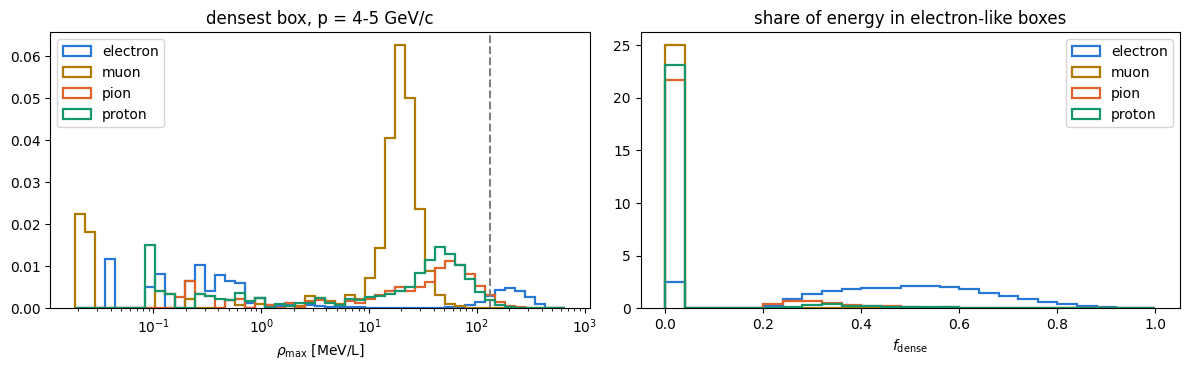

p=9-10: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.447
p=9-10: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=9-10: pion     share of events with an electron-like box:  9.9%   mean f_dense = 0.033
p=9-10: proton   share of events with an electron-like box:  3.4%   mean f_dense = 0.012


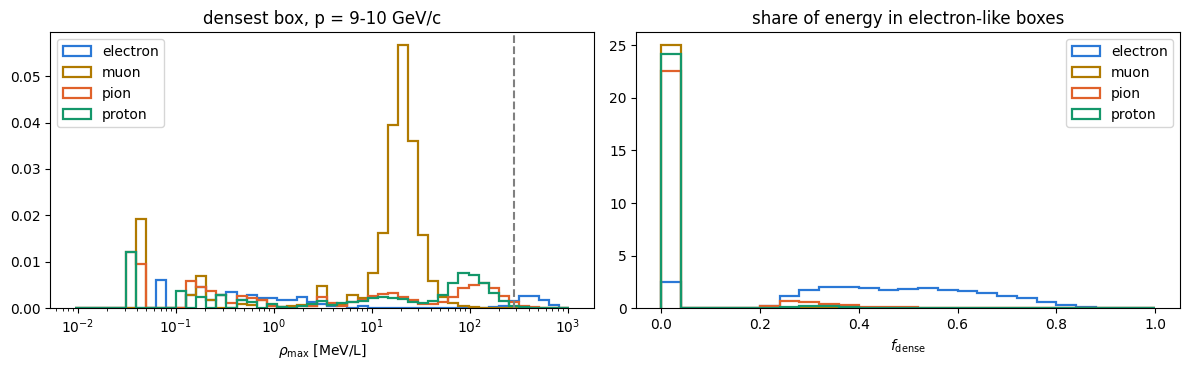

p=19-20: electron share of events with an electron-like box: 90.0%   mean f_dense = 0.439
p=19-20: muon     share of events with an electron-like box:  0.0%   mean f_dense = 0.000
p=19-20: pion     share of events with an electron-like box:  8.1%   mean f_dense = 0.027
p=19-20: proton   share of events with an electron-like box:  1.6%   mean f_dense = 0.005


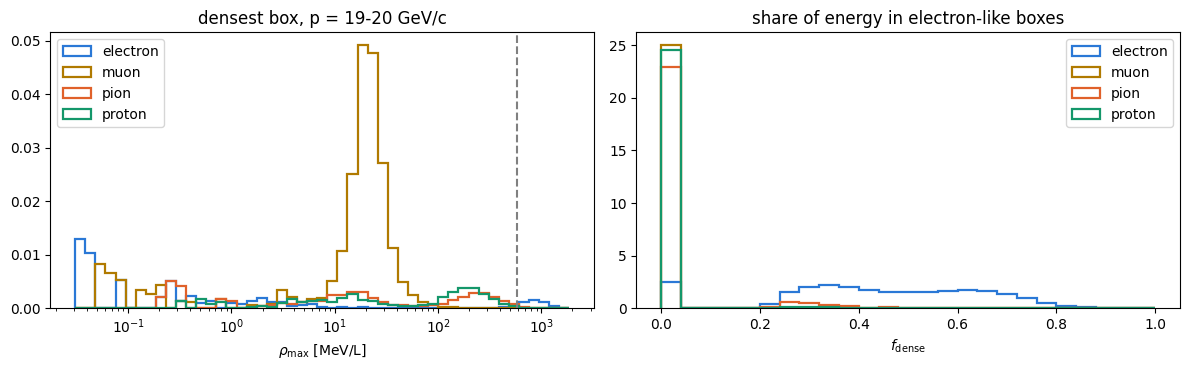

In [8]:
def local_features(lo, hi, q=0.10):
    thr = EV["electron"].query("@lo <= p < @hi").rho_max.quantile(q)
    out = {}
    for n in NAMES:
        b = pd.read_parquet(WORK_DIR / f"boxes_{n}.parquet", columns=["event", "p", "E"],
                            filters=[("p", ">=", lo), ("p", "<", hi)])
        b["rho"] = 1000 * b.E / BOX_L
        g = b.groupby("event")
        f = pd.DataFrame({"rho_max": g.rho.max(),
                          "f_dense": b.E.where(b.rho >= thr, 0).groupby(b.event).sum() / g.E.sum()})
        out[n] = f
    return thr, out

for lo, hi in [(4, 5), (9, 10), (19, 20)]:
    thr, F = local_features(lo, hi)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    bins = np.logspace(np.log10(max(min(f.rho_max.min() for f in F.values()), 1e-3)),
                       np.log10(max(f.rho_max.max() for f in F.values())), 50)
    for n, f in F.items():
        ax[0].hist(f.rho_max, bins=bins, histtype="step", density=True, color=COLORS[n], label=n, lw=1.6)
        ax[1].hist(f.f_dense, bins=np.linspace(0, 1, 26), histtype="step", density=True, color=COLORS[n], label=n, lw=1.6)
        print(f"p={lo}-{hi}: {n:8s} share of events with an electron-like box: {np.mean(f.rho_max >= thr):5.1%}"
              f"   mean f_dense = {f.f_dense.mean():.3f}")
    ax[0].axvline(thr, ls="--", c="grey"); ax[0].set(xscale="log", xlabel=r"$\rho_{\max}$ [MeV/L]", title=f"densest box, p = {lo}-{hi} GeV/c")
    ax[1].set(xlabel=r"$f_{\rm dense}$", title="share of energy in electron-like boxes")
    for a in ax: a.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / f"local_density_{lo}_{hi}GeV.png", dpi=130); plt.show()

## 5. Checks and the connection to issue #1 (added in the repository)

1. **Reproduction:** the numbers of this run against the outputs of her original notebook.
2. **Two samples:** her events combine s1 and s2 (event id = file number × 10⁷ + `event_number`, files sorted: 1 = s1, 2 = s2); the
   median density per momentum bin and the share of electron-like boxes, per sample, with their statistical errors.
3. **Per-event features** for further use: `results/density/<particle>.parquet` (sample, `event_number`, p, E_tot, V95_L, `rho95`,
   `rho_max`), joinable with `results/features/<particle>.parquet` (s1) on `event_number`.
4. **ρ̄95 as a feature** (her issue asks for the AUC per bin): AUC on the test split of the s1 events in the fiducial selection of
   issue #1, compared with the core fraction `f_core` and with both together (logistic regression on log ρ̄95 and f_core, trained on the
   train split). For pion vs. proton the AUC is the probability that the proton has the larger value: below 0.5 means that protons
   are less dense (have less core); the combination is oriented and lies above 0.5. Note: ρ̄95 uses all deposits and her shower frame;
   f_core uses prompt deposits (t < 100 ns) and the issue #1 axis.

In [9]:
import json, re
def auc_hm(neg, pos):
    """P(score of pos > score of neg), ties counted 1/2, with the Hanley-McNeil error (rank formula; no extra packages)."""
    neg, pos = np.asarray(neg, float), np.asarray(pos, float)
    neg, pos = neg[np.isfinite(neg)], pos[np.isfinite(pos)]
    r = pd.Series(np.r_[neg, pos]).rank().values
    n1, n2 = len(pos), len(neg)
    a = (r[n2:].sum() - n1 * (n1 + 1) / 2) / (n1 * n2)
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return float(a), float(np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n2 - 1) * (q2 - a * a)) / (n1 * n2)))

SHARES = {}
for lo, hi in [(4, 5), (9, 10), (19, 20)]:
    thr, F = local_features(lo, hi)
    for n, f in F.items():
        SHARES[(lo, n)] = float(np.mean(f.rho_max >= thr))
REPRO = None
ORIG = Path("notebooks/sofiya/energy_density.ipynb")
if not ORIG.exists():
    print(f"{ORIG} not found: the reproduction check is skipped")
else:
    orig = json.load(open(ORIG, encoding="utf-8"))
    def out_text(i):
        t = ""
        for o in orig["cells"][i].get("outputs", []):
            t += "".join(o.get("text", [])) if o.get("output_type") == "stream" else "".join(o.get("data", {}).get("text/plain", []))
        return t
    # her table of median rho95 (cell 5) against this run
    rows = [l.split() for l in out_text(5).splitlines()[2:] if re.match(r"^\d+-\d+", l)]
    hers = pd.DataFrame([[float(x) for x in r[1:]] for r in rows], index=[r[0] for r in rows], columns=["electron", "muon", "pion", "proton"])
    mine = GLOBAL.pivot(index="bin", columns="particle", values="rho95_median").reindex(hers.index)[hers.columns]
    dev = (mine.round(2) - hers).abs()
    print(f"median rho95: {dev.size} values, max |this run - hers| = {dev.values.max():.3f} MeV/L")
    # her shares of events with an electron-like box (cell 13) against this run
    hs = {(int(m.group(1)), m.group(3)): float(m.group(4)) / 100 for m in re.finditer(r"p=(\d+)-(\d+): (\w+)\s+share of events with an electron-like box:\s+([\d.]+)%", out_text(13))}
    d = max(abs(SHARES[k] - v) for k, v in hs.items())
    print(f"electron-like box shares: {len(hs)} values, max |this run - hers| = {100 * d:.2f} percentage points")
    REPRO = {"rho95_max_abs_diff": float(dev.values.max()), "shares_max_abs_diff": float(d), "n_rho95": int(dev.size), "n_shares": len(hs)}

median rho95: 80 values, max |this run - hers| = 0.000 MeV/L
electron-like box shares: 12 values, max |this run - hers| = 0.04 percentage points


In [10]:
rng = np.random.default_rng(12345)
def med_se(x, n_boot=200):
    x = np.asarray(x)
    return float(np.median(x)), float(np.std([np.median(rng.choice(x, len(x))) for _ in range(n_boot)], ddof=1))
rows = []
for n, ev in EV.items():
    smp = (ev.index.values // 10_000_000).astype(int)
    for pb in (0, 1, 4, 9, 14, 19):
        r = {"particle": n, "bin": f"{pb}-{pb + 1}"}
        for s in (1, 2):
            v = ev.rho95.values[(smp == s) & (ev.pbin.values == pb)]
            r[f"s{s}"], r[f"s{s}_se"] = med_se(v)
        r["z"] = (r["s1"] - r["s2"]) / np.hypot(r["s1_se"], r["s2_se"])
        rows.append(r)
TWO = pd.DataFrame(rows)
display(TWO.round(3))
rows = []
for lo, hi in [(4, 5), (9, 10), (19, 20)]:
    thr, F = local_features(lo, hi)
    for n in ("pion", "proton"):
        f = F[n]; smp = (f.index.values // 10_000_000).astype(int)
        r = {"particle": n, "p": f"{lo}-{hi}"}
        for s in (1, 2):
            k = (f.rho_max.values[smp == s] >= thr)
            r[f"s{s}"], r[f"s{s}_se"] = float(k.mean()), float(np.sqrt(k.mean() * (1 - k.mean()) / len(k)))
        r["z"] = (r["s1"] - r["s2"]) / np.hypot(r["s1_se"], r["s2_se"])
        rows.append(r)
TWO_SHARES = pd.DataFrame(rows)
display(TWO_SHARES.round(4))
print(f"largest |z| between the samples: rho95 medians {TWO.z.abs().max():.2f}, electron-like shares {TWO_SHARES.z.abs().max():.2f}")

,particle,bin,s1,s1_se,s2,s2_se,z
0,electron,0-1,10.844,0.118,10.788,0.156,0.287
1,electron,1-2,22.880,0.130,22.641,0.138,1.265
2,electron,4-5,49.132,0.247,49.172,0.220,-0.122
3,electron,9-10,84.483,0.416,85.376,0.405,-1.536
4,electron,14-15,116.950,0.472,117.179,0.540,-0.320
5,electron,19-20,147.455,0.554,149.403,0.584,-2.419
6,muon,0-1,8.706,0.050,8.765,0.042,-0.901
7,muon,1-2,9.230,0.026,9.205,0.032,0.618
8,muon,4-5,10.138,0.042,10.114,0.041,0.407
9,muon,9-10,10.462,0.060,10.480,0.053,-0.224


,particle,p,s1,s1_se,s2,s2_se,z
0,pion,4-5,0.1264,0.0047,0.1378,0.0049,-1.6836
1,proton,4-5,0.0736,0.0037,0.0742,0.0037,-0.1147
2,pion,9-10,0.0996,0.0042,0.0988,0.0042,0.1338
3,proton,9-10,0.0328,0.0025,0.0348,0.0026,-0.5534
4,pion,19-20,0.0826,0.0039,0.0786,0.0038,0.7347
5,proton,19-20,0.0162,0.0018,0.0156,0.0018,0.2398


largest |z| between the samples: rho95 medians 2.42, electron-like shares 1.68


In [11]:
for n, ev in EV.items():
    smp = (ev.index.values // 10_000_000).astype(int)
    out = pd.DataFrame({"sample": np.where(smp == 1, "s1", "s2"), "event_number": (ev.index.values % 10_000_000).astype(np.int64),
                        "p": ev.p.values, "E_tot": ev.E_tot.values.astype(np.float32), "V95_L": ev.V95_L.values.astype(np.float32),
                        "rho95": ev.rho95.values.astype(np.float32), "rho_max": ev.rho_max.values.astype(np.float32)})
    out.to_parquet(FIG_DIR / f"{n}.parquet", index=False, compression="zstd")
    print(n, len(out), "events ->", FIG_DIR / f"{n}.parquet")

electron 200000 events -> results/density/electron.parquet


muon 200000 events -> results/density/muon.parquet
pion 200000 events -> results/density/pion.parquet


proton 200000 events -> results/density/proton.parquet


{'electron': 59475, 'muon': 59414, 'pion': 59333, 'proton': 59257} events (s1, fiducial, joined)


,pair,bin,auc_rho95,se_rho95,auc_fcore,se_fcore,auc_both,se_both
1,electron vs pion,1,0.901,0.011,0.985,0.004,0.987,0.004
2,electron vs pion,2,0.982,0.004,1.000,0.001,1.000,0.001
4,electron vs pion,4,0.991,0.003,0.998,0.001,0.999,0.001
9,electron vs pion,9,0.997,0.002,0.999,0.001,0.999,0.001
14,electron vs pion,14,0.997,0.002,0.998,0.002,0.998,0.002
19,electron vs pion,19,0.995,0.002,0.996,0.002,0.996,0.002
21,electron vs proton,1,0.857,0.013,0.977,0.005,0.979,0.005
22,electron vs proton,2,0.982,0.004,0.997,0.002,0.998,0.002
24,electron vs proton,4,0.999,0.001,1.000,0.000,1.000,0.000
29,electron vs proton,9,1.000,0.000,1.000,0.000,1.000,0.000


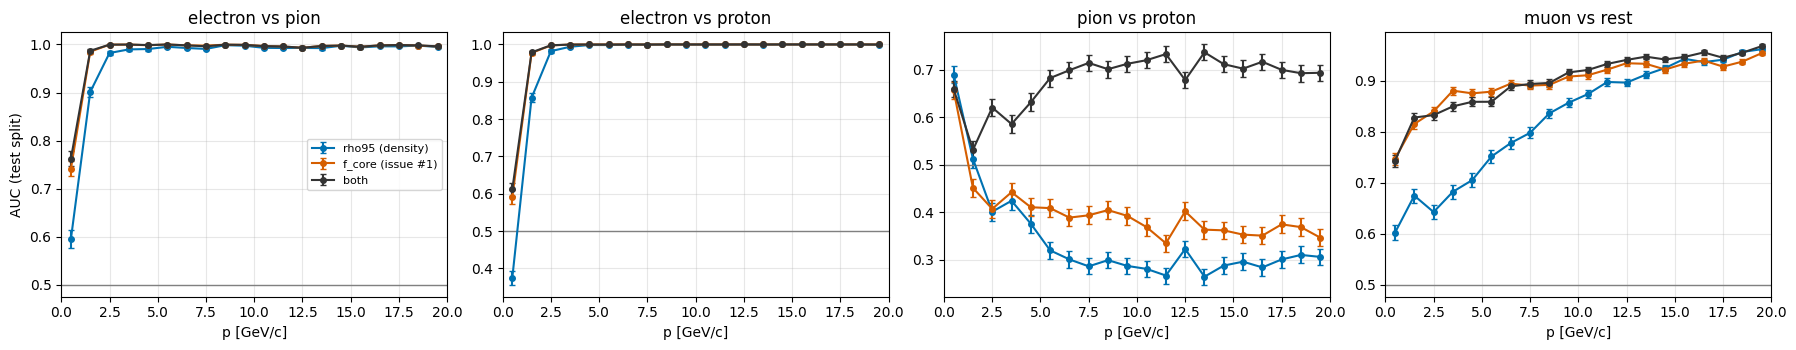

{
 "reproduction": {
  "rho95_max_abs_diff": 0.0,
  "shares_max_abs_diff": 0.0003999999999999976,
  "n_rho95": 80,
  "n_shares": 12
 },
 "rho95_median_9_10": {
  "electron": 84.9200771183074,
  "muon": 10.473370890624164,
  "pion": 17.782115508852165,
  "proton": 13.486647034989943
 },
 "electron_like_share": {
  "pion|4": 0.1321,
  "proton|4": 0.0739,
  "pion|9": 0.0992,
  "proton|9": 0.0338,
  "pion|19": 0.0806,
  "proton|19": 0.0159
 },
 "two_samples_max_abs_z": {
  "rho95": 2.419074343636901,
  "shares": 1.6836435376487564
 },
 "auc_2_20": {
  "electron vs pion": {
   "auc_rho95": [
    0.9822687270603937,
    0.9985653983815749
   ],
   "auc_fcore": [
    0.9931037689065212,
    0.9999534016775397
   ],
   "auc_both": [
    0.9932019175138441,
    0.9999637568603086
   ]
  },
  "electron vs proton": {
   "auc_rho95": [
    0.9820664891470992,
    1.0
   ],
   "auc_fcore": [
    0.9973220769789397,
    1.0
   ],
   "auc_both": [
    0.9977860485758089,
    1.0
   ]
  },
  "pion vs 

In [12]:
def logreg(X, y, n_iter=30):
    """Logistic regression by Newton steps (no extra packages); returns the linear score function."""
    mu, sd = X.mean(0), X.std(0) + 1e-12
    Z = np.c_[np.ones(len(X)), (X - mu) / sd]
    w = np.zeros(Z.shape[1])
    for _ in range(n_iter):
        p = 1 / (1 + np.exp(-Z @ w))
        w += np.linalg.solve(Z.T @ (Z * (p * (1 - p))[:, None]) + 1e-6 * np.eye(len(w)), Z.T @ (y - p))
    return lambda X2: np.c_[np.ones(len(X2)), (X2 - mu) / sd] @ w

FEAT = {n: Path(f"results/features/{n}.parquet") for n in NAMES}
if not all(f.exists() for f in FEAT.values()):
    print("results/features/<particle>.parquet (issue #1) not found: the comparison with f_core is skipped")
    AUC = None
else:
    J = {}
    for n, ev in EV.items():
        smp = (ev.index.values // 10_000_000).astype(int)
        d = pd.DataFrame({"event_number": (ev.index.values % 10_000_000).astype(np.int64), "rho95": ev.rho95.values})[smp == 1]
        f = pd.read_parquet(FEAT[n], columns=["event_number", "split", "bin", "entry_inside", "fiducial", "E_vis", "f_core_strict"])
        f = f[f.entry_inside & f.fiducial & (f.E_vis > 0)]
        J[n] = f.merge(d, on="event_number", how="inner")
    print({n: len(j) for n, j in J.items()}, "events (s1, fiducial, joined)")
    PAIRS = [("electron", "pion", -1), ("electron", "proton", -1), ("pion", "proton", +1), ("muon", "rest", +1)]   # sign: the second scores high
    rows = []
    for a, b, sgn in PAIRS:
        for k in range(20):
            A_ = J[a][J[a].bin == k]
            B_ = pd.concat([J[x] for x in ("electron", "pion", "proton")]) if b == "rest" else J[b]
            B_ = B_[B_.bin == k]
            tr = pd.concat([A_[A_.split == "train"].assign(y=0), B_[B_.split == "train"].assign(y=1)])
            te_a, te_b = A_[A_.split == "test"], B_[B_.split == "test"]
            X = lambda t: np.c_[np.log(np.maximum(t.rho95.values, 1e-3)), t.f_core_strict.values]
            score = logreg(X(tr), tr.y.values.astype(float))
            r = {"pair": f"{a} vs {b}", "bin": k}
            r["auc_rho95"], r["se_rho95"] = auc_hm(sgn * te_a.rho95.values, sgn * te_b.rho95.values)
            r["auc_fcore"], r["se_fcore"] = auc_hm(sgn * te_a.f_core_strict.values, sgn * te_b.f_core_strict.values)
            r["auc_both"], r["se_both"] = auc_hm(score(X(te_a)), score(X(te_b)))
            rows.append(r)
    AUC = pd.DataFrame(rows)
    AUC.round(4).to_csv(FIG_DIR / "auc_rho95_fcore.csv", index=False)
    display(AUC[AUC.bin.isin([1, 2, 4, 9, 14, 19])].round(3))
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
    for a_, (pair, g) in zip(ax, AUC.groupby("pair", sort=False)):
        for c, lab, col in (("auc_rho95", "rho95 (density)", "#0072B2"), ("auc_fcore", "f_core (issue #1)", "#D55E00"), ("auc_both", "both", "0.2")):
            a_.errorbar(g.bin + 0.5, g[c], yerr=g[c.replace("auc", "se")], fmt="o-", ms=4, capsize=2, color=col, label=lab)
        a_.axhline(0.5, color="0.5", lw=1); a_.set(title=pair, xlabel="p [GeV/c]", xlim=(0, 20)); a_.grid(alpha=.3)
    ax[0].set_ylabel("AUC (test split)"); ax[0].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG_DIR / "auc_rho95_fcore.png", dpi=130); plt.show()
SUMMARY = {"reproduction": REPRO,
           "rho95_median_9_10": {n: float(GLOBAL[(GLOBAL.particle == n) & (GLOBAL.bin == "9-10")].rho95_median.iloc[0]) for n in NAMES},
           "electron_like_share": {f"{n}|{lo}": SHARES[(lo, n)] for lo in (4, 9, 19) for n in ("pion", "proton")},
           "two_samples_max_abs_z": {"rho95": float(TWO.z.abs().max()), "shares": float(TWO_SHARES.z.abs().max())}}
if AUC is not None:
    hi = AUC[AUC.bin >= 2]
    SUMMARY["auc_2_20"] = {p: {c: [float(hi[hi.pair == p][c].min()), float(hi[hi.pair == p][c].max())] for c in ("auc_rho95", "auc_fcore", "auc_both")}
                           for p in AUC.pair.unique()}
json.dump(SUMMARY, open(FIG_DIR / "summary.json", "w"), indent=1)
print(json.dumps(SUMMARY, indent=1))